## Introduction to Quantum Computing: Labs

### Lab 8: Grover on Quantum Hardware

In this lab, we will run the **Grover algorithm** on simulated and real quantum hardware. We will reuse the circuits from Lab 7 and compare the variants with and without an ancilla qubit.

First, we will implement both Grover variants, explore the available backends, and transpile our circuits. We will then compare the measurement results from the simulator with those from a real **IBM Quantum** computer.

You will need an account to access the IBM Quantum Cloud. You can register for free at <https://quantum.cloud.ibm.com/signin> and use the free computing time available with the Open Plan.

If you would prefer not to create your own account, please speak to me. I can provide access for this lab session.

In **Exercise 7**, you will apply Grover to another problem: 2×2 map coloring.

### Exercise 1: Implementing the Grover Algorithm

First, we will write two Python functions that create a circuit for the Grover algorithm. The number of data qubits and Grover steps should be configurable.

As in Lab 7, we will search for the state in which all data qubits have the value 1, i.e. $\ket{1\ldots1}$.

We will reuse the functions for the uniform superposition (`initial_state`) and amplitude amplification (`amplitude_amplification`) without changes. We can combine the subcircuits using `compose`.

We will implement two variants of the oracle:

- A variant without an ancilla qubit
- A variant with one ancilla qubit

Both variants require a multi-controlled X gate (`mcx`). We will add measurements later.

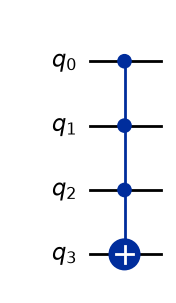

In [66]:
from qiskit import QuantumCircuit
from IPython.display import display

quantum_circuit = QuantumCircuit(4)
quantum_circuit.mcx([0, 1, 2], 3)
quantum_circuit.draw("mpl")

In [67]:
# Example of combining two circuits using compose
quantum_circuit1 = QuantumCircuit(1)
quantum_circuit2 = QuantumCircuit(1)
quantum_circuit1.compose(quantum_circuit2, inplace=True)

**Exercise 1.1:** Implement the Grover algorithm **without an ancilla qubit** for a configurable number of data qubits and Grover steps.

Use the provided functions for the initial state and amplitude amplification:

- `initial_state(num_data_qubits, num_ancilla_qubits)` creates a uniform superposition of the data qubits. The ancilla qubits remain in the state $\ket{0}$.
- `amplitude_amplification(num_data_qubits, num_ancilla_qubits)` creates the amplitude amplification circuit for the data qubits.

Both functions require **two arguments**. When working without an ancilla qubit, set `num_ancilla_qubits=0`.

Implement the oracle yourself using a multi-controlled Z gate. We can construct this from an `mcx` gate and two Hadamard gates on its target qubit, using the relation $HXH = Z$.

Prepare the superposition once. Then, for each Grover step, apply the oracle followed by amplitude amplification.

In [68]:
from qc_lecture_tools.grover import (
    initial_state,
    amplitude_amplification,
    print_grover_states,
)

In [69]:
def grover(num_data_qubits: int, num_steps: int) -> QuantumCircuit:
    """Finds the state |1...1> without an ancilla qubit.

    Args:
        num_data_qubits: Number of data qubits.
        num_steps: Number of Grover steps.

    Returns:
        Grover circuit without measurements.
    """
    quantum_circuit = QuantumCircuit(num_data_qubits)

    # Prepare a uniform superposition of the data qubits
    quantum_circuit.compose(initial_state(num_data_qubits, 0), inplace=True)
    control_qubits = list(range(num_data_qubits - 1))
    target_qubit = num_data_qubits - 1

    for _ in range(num_steps):
        # Oracle: A multi-controlled Z gate marks the state |1...1>.
        quantum_circuit.h(target_qubit)
        quantum_circuit.mcx(control_qubits, target_qubit)
        quantum_circuit.h(target_qubit)

        # Amplitude amplification on the data qubits
        quantum_circuit.compose(
            amplitude_amplification(num_data_qubits, 0), inplace=True
        )

    return quantum_circuit

Use the following code to visualize the resulting quantum circuit:

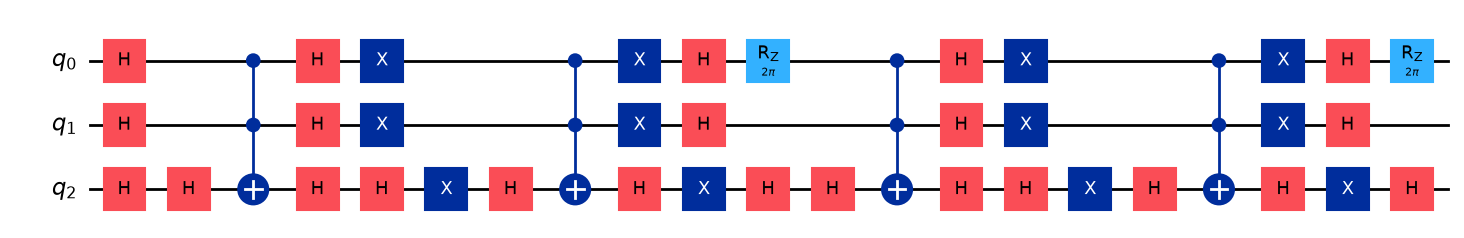

In [70]:
num_data_qubits = 3
num_steps = 2

quantum_circuit = grover(num_data_qubits, num_steps)
quantum_circuit.draw("mpl")

Check whether your implementation produces the expected result. Use `print_grover_states(quantum_circuit, num_data_qubits)` to display the resulting quantum state.

In [71]:
num_data_qubits = 3
num_steps = 2

quantum_circuit = grover(num_data_qubits, num_steps)
print_grover_states(quantum_circuit, num_data_qubits)

Found basis states with non-zero amplitudes:
000: -0.09  Probability:  0.01
001: -0.09  Probability:  0.01
010: -0.09  Probability:  0.01
011: -0.09  Probability:  0.01
100: -0.09  Probability:  0.01
101: -0.09  Probability:  0.01
110: -0.09  Probability:  0.01
111:  0.97  Probability:  0.95


**Exercise 1.2:** Now implement the Grover algorithm **with one additional ancilla qubit** using the compute–uncompute principle.

1. **Compute:** Store whether all data qubits have the value 1 in the ancilla qubit.
2. **Phase marking:** Apply a Z gate to the ancilla qubit. This flips the sign of the target state's amplitude.
3. **Uncompute:** Undo the computation. The ancilla qubit is then back in the state $\ket{0}$ and disentangled from the data qubits.

Only the data qubits are initially placed in superposition. The ancilla qubit starts in the state $\ket{0}$. Use `num_ancilla_qubits=1` for both helper functions.

In [72]:
def grover_ancilla(num_data_qubits: int, num_steps: int) -> QuantumCircuit:
    """Finds the state |1...1> with one ancilla qubit.

    Args:
        num_data_qubits: Number of data qubits.
        num_steps: Number of Grover steps.

    Returns:
        Grover circuit without measurements; the ancilla qubit ends in |0>.
    """
    quantum_circuit = QuantumCircuit(num_data_qubits + 1)

    # Place only the data qubits in superposition; the ancilla remains in |0>.
    quantum_circuit.compose(initial_state(num_data_qubits, 1), inplace=True)
    control_qubits = list(range(num_data_qubits))
    ancilla_qubit = num_data_qubits

    for _ in range(num_steps):
        # Compute: Check whether all data qubits have the value 1
        quantum_circuit.mcx(control_qubits, ancilla_qubit)
        # Phase marking of the target state
        quantum_circuit.z(ancilla_qubit)
        # Uncompute: Return the ancilla to |0>
        quantum_circuit.mcx(control_qubits, ancilla_qubit)

        quantum_circuit.compose(
            amplitude_amplification(num_data_qubits, 1), inplace=True
        )

    return quantum_circuit

Use the following code to visualize the resulting quantum circuit:

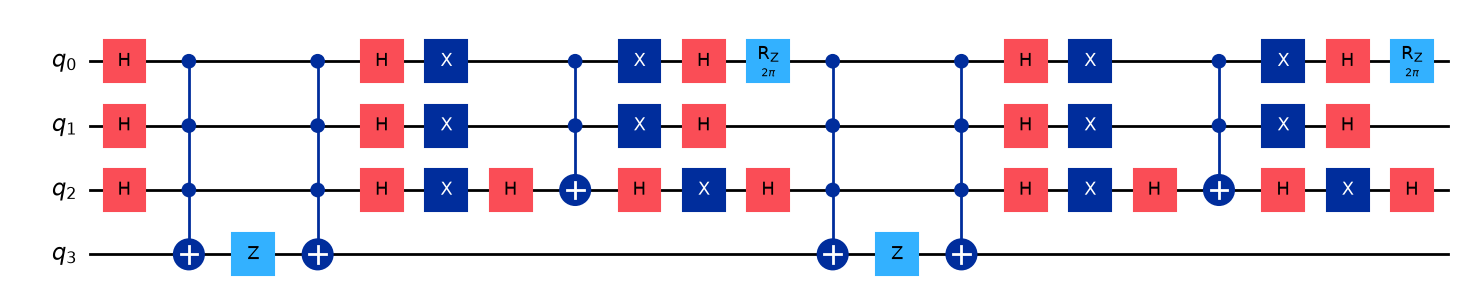

In [73]:
num_data_qubits = 3
num_steps = 2

quantum_circuit = grover_ancilla(num_data_qubits, num_steps)
quantum_circuit.draw("mpl")

Check whether your implementation produces the expected result. Is the ancilla qubit back in the state $\ket{0}$ at the end?

In [74]:
num_data_qubits = 3
num_steps = 2

quantum_circuit = grover_ancilla(num_data_qubits, num_steps)
print_grover_states(quantum_circuit, num_data_qubits)

Found basis states with non-zero amplitudes:
000 0: -0.09  Probability:  0.01
001 0: -0.09  Probability:  0.01
010 0: -0.09  Probability:  0.01
011 0: -0.09  Probability:  0.01
100 0: -0.09  Probability:  0.01
101 0: -0.09  Probability:  0.01
110 0: -0.09  Probability:  0.01
111 0:  0.97  Probability:  0.95


**Exercise 1.3:** For **4 and 5 data qubits**, find a suitable number of Grover steps to maximize the probability of measuring the target state. Compare several step counts using `print_grover_states`.

In [75]:
# 4 data qubits: 3 Grover steps
num_data_qubits = 4
num_steps = 3

quantum_circuit = grover(num_data_qubits, num_steps)
print_grover_states(quantum_circuit, num_data_qubits)


Found basis states with non-zero amplitudes:
0000: -0.05  Probability:  0.00
0001: -0.05  Probability:  0.00
0010: -0.05  Probability:  0.00
0011: -0.05  Probability:  0.00
0100: -0.05  Probability:  0.00
0101: -0.05  Probability:  0.00
0110: -0.05  Probability:  0.00
0111: -0.05  Probability:  0.00
1000: -0.05  Probability:  0.00
1001: -0.05  Probability:  0.00
1010: -0.05  Probability:  0.00
1011: -0.05  Probability:  0.00
1100: -0.05  Probability:  0.00
1101: -0.05  Probability:  0.00
1110: -0.05  Probability:  0.00
1111:  0.98  Probability:  0.96


In [76]:
# 5 data qubits: 4 Grover steps
num_data_qubits = 5
num_steps = 4

quantum_circuit = grover(num_data_qubits, num_steps)
print_grover_states(quantum_circuit, num_data_qubits)


Found basis states with non-zero amplitudes:
00000: -0.01  Probability:  0.00
00001: -0.01  Probability:  0.00
00010: -0.01  Probability:  0.00
00011: -0.01  Probability:  0.00
00100: -0.01  Probability:  0.00
00101: -0.01  Probability:  0.00
00110: -0.01  Probability:  0.00
00111: -0.01  Probability:  0.00
01000: -0.01  Probability:  0.00
01001: -0.01  Probability:  0.00
01010: -0.01  Probability:  0.00
01011: -0.01  Probability:  0.00
01100: -0.01  Probability:  0.00
01101: -0.01  Probability:  0.00
01110: -0.01  Probability:  0.00
01111: -0.01  Probability:  0.00
10000: -0.01  Probability:  0.00
10001: -0.01  Probability:  0.00
10010: -0.01  Probability:  0.00
10011: -0.01  Probability:  0.00
10100: -0.01  Probability:  0.00
10101: -0.01  Probability:  0.00
10110: -0.01  Probability:  0.00
10111: -0.01  Probability:  0.00
11000: -0.01  Probability:  0.00
11001: -0.01  Probability:  0.00
11010: -0.01  Probability:  0.00
11011: -0.01  Probability:  0.00
11100: -0.01  Probability:  0.0

### Exercise 2: Registering with IBM Quantum

Open <https://quantum.cloud.ibm.com/signin> and create an IBM Cloud account if needed. Follow the registration steps.

If you are redirected to the general IBM Cloud website during registration, open <https://quantum.cloud.ibm.com/> again afterwards.

Sign in to the IBM Quantum Platform and check whether an instance is available to you. If you do not have one yet, create an instance using the free **Open Plan**.

On the dashboard, create an API key under **API key**. Give it a name, confirm its creation, and copy the key to a safe place. We will need it in Exercise 3.

If registration does not work or you would prefer not to create your own account, please speak to me.

### Exercise 3: Connecting to IBM Quantum

We can use the API key to connect to the IBM Quantum Cloud and list the available quantum computers. We will then examine the properties of different backends.

**Exercise 3.1:** Connect to the IBM Quantum Cloud and list the available backends.

To do this, we create a `QiskitRuntimeService` object. Pass your API key as `token`. You can then access the hardware backends through the returned service object.

Replace `ENTER_YOUR_API_KEY_HERE` with your API key in the following cell and run it.

For setup instructions, see the [IBM documentation](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/initialize-account).

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Enter your own API key between the quotation marks.
service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token="ENTER_YOUR_API_KEY_HERE",
)
service.backends()

qiskit_runtime_service._discover_account:WARNING:2026-11-19 20:52:03,192: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-19 20:52:06,890: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: HHN. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-19 20:52:06,891: Loading instance: HHN, plan: open


[<IBMBackend('ibm_fez')>,
 <IBMBackend('ibm_kingston')>,
 <IBMBackend('ibm_marrakesh')>]

**Exercise 3.2:** Select an available quantum backend.

Use `service.backend()` to obtain a backend object. Pass the name of the desired backend, for example:

```python
backend_fez = service.backend("ibm_fez")
```

If this backend is not available to your account, choose a name from the output of `service.backends()`. Use your chosen backend in place of `backend_fez` throughout the rest of the lab.

Examine:

- The number of qubits (`backend_fez.num_qubits`)
- The operations available on the hardware (`backend_fez.operation_names`)

Compare the gates in your Grover implementation with the gates available on the hardware.

In [78]:
# Select a backend; use another available name if needed.
backend_fez = service.backend("ibm_fez")
print("Number of qubits:", backend_fez.num_qubits)
print("Available operations:", backend_fez.operation_names)

qiskit_runtime_service.backends:WARNING:2026-11-19 20:52:08,434: Using instance: HHN, plan: open


Number of qubits: 156
Available operations: ['measure', 'if_else', 'measure_2', 'measure_reset_2', 'rz', 'delay', 'reset_2', 'id', 'sx', 'reset', 'xslow', 'cz', 'measure_reset', 'x']


**Observation:** The hardware's native gates differ from the gates in our original quantum circuit.

**Exercise 3.3:** For testing, we will first use a simulated quantum backend. It provides the same interface as the real hardware, but does not consume computing time on a quantum computer.

The following cell creates the `FakeManilaV2` backend. Determine its number of qubits and available operations as well.

The fake backend models properties of a real device. When run with Qiskit Aer, it also uses a noise model, so it is not an ideal simulator. For more information, see the [IBM documentation on local testing](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/local-testing-mode).

In [79]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

backend_fake_manila = FakeManilaV2()

In [80]:
print("Number of qubits:", backend_fake_manila.num_qubits)
print("Available operations:", backend_fake_manila.operation_names)

Number of qubits: 5
Available operations: ['measure', 'if_else', 'delay', 'rz', 'for_loop', 'id', 'sx', 'reset', 'switch_case', 'cx', 'x']


### Exercise 4: Transpiling

In Exercise 3, we saw that a quantum computer provides only certain native gates. One example is `sx`, or $\sqrt{X}$, the square root of the X gate.

A universal gate set allows us to construct any quantum gate from its elements or approximate it with sufficient accuracy. Before running a circuit on hardware, we need to translate it into the device's native gates. This process is called **transpiling**.

Transpilation can also optimize the circuit:

- Redundant gates, such as $XX = I$, are removed.
- Gates are reordered when this preserves the circuit's effect.
- Logical qubits are mapped to physical qubits. The hardware's connectivity and error rates can be taken into account.

Transpiling is therefore similar to compiling a classical program.

In Qiskit, we use the `transpile` function. It takes a quantum circuit and a backend and returns the transpiled circuit.

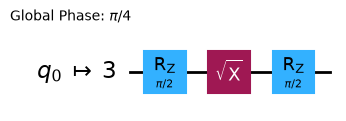

In [81]:
from qiskit.compiler import transpile

# Example: Translate a Hadamard gate into the backend's native gates.
quantum_circuit1 = QuantumCircuit(1)
quantum_circuit1.h(0)
transpiled_circuit = transpile(quantum_circuit1, backend=backend_fake_manila)
transpiled_circuit.draw("mpl")


**Exercise 4.1:** Transpile your Grover implementation **without an ancilla qubit** for **3 data qubits and one Grover step**.

Use the simulated backend `backend_fake_manila` and the real backend `backend_fez` selected in Exercise 3, creating a transpiled circuit for each.

Visualize the original circuit and both transpiled circuits using `draw("mpl")`. Also compare the counts of each gate using `count_ops()`.

Original circuit: OrderedDict({'h': 13, 'x': 6, 'ccx': 2, 'rz': 1})


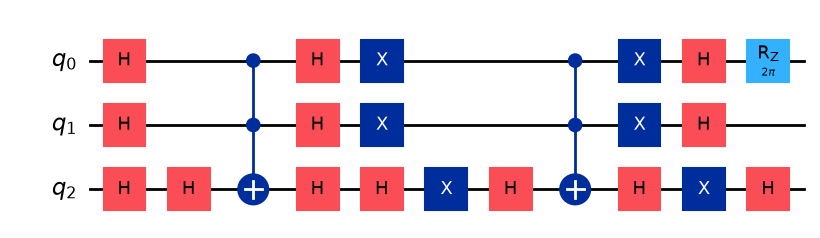

Simulated backend: OrderedDict({'rz': 27, 'cx': 19, 'sx': 11, 'x': 1})


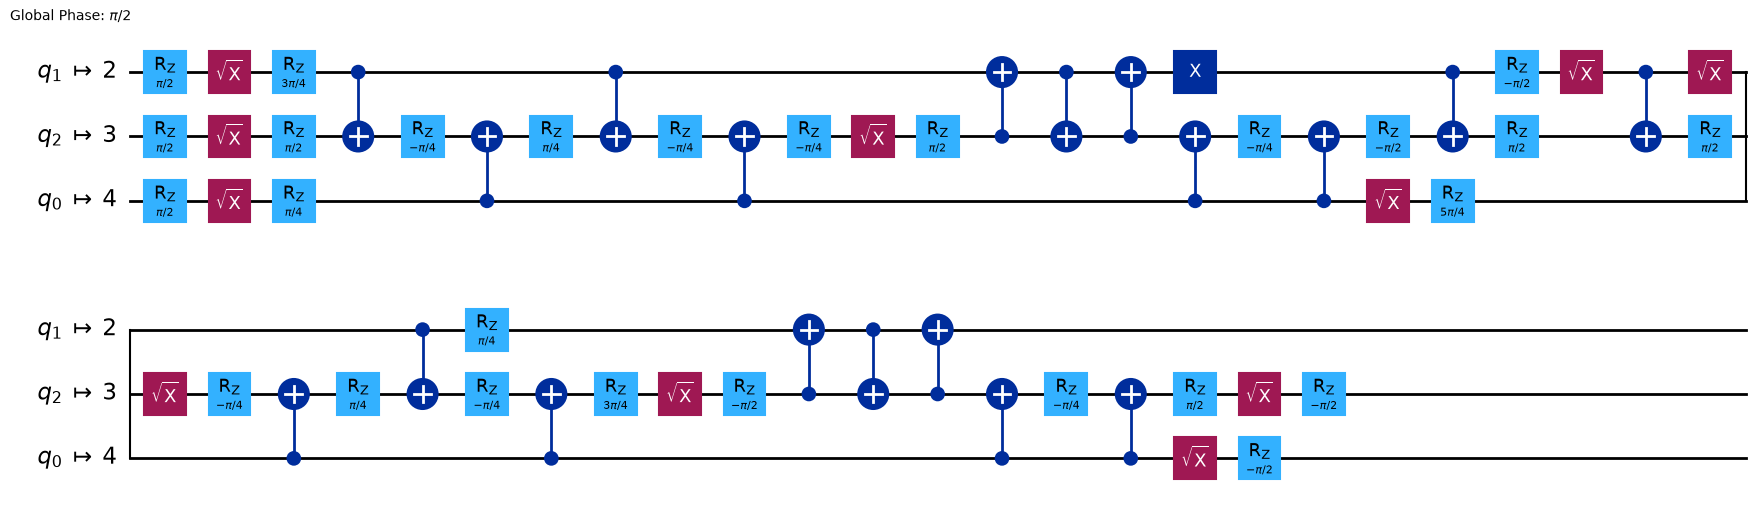

In [82]:
# Grover circuit without an ancilla qubit
quantum_circuit = grover(3, 1)
print("Original circuit:", quantum_circuit.count_ops())
display(quantum_circuit.draw("mpl"))

# Transpile for the simulated backend
quantum_circuit_transpiled = transpile(
    quantum_circuit, backend=backend_fake_manila
)
print("Simulated backend:", quantum_circuit_transpiled.count_ops())
display(quantum_circuit_transpiled.draw("mpl", idle_wires=False))

Real backend: OrderedDict({'sx': 36, 'rz': 31, 'cz': 19, 'x': 6})


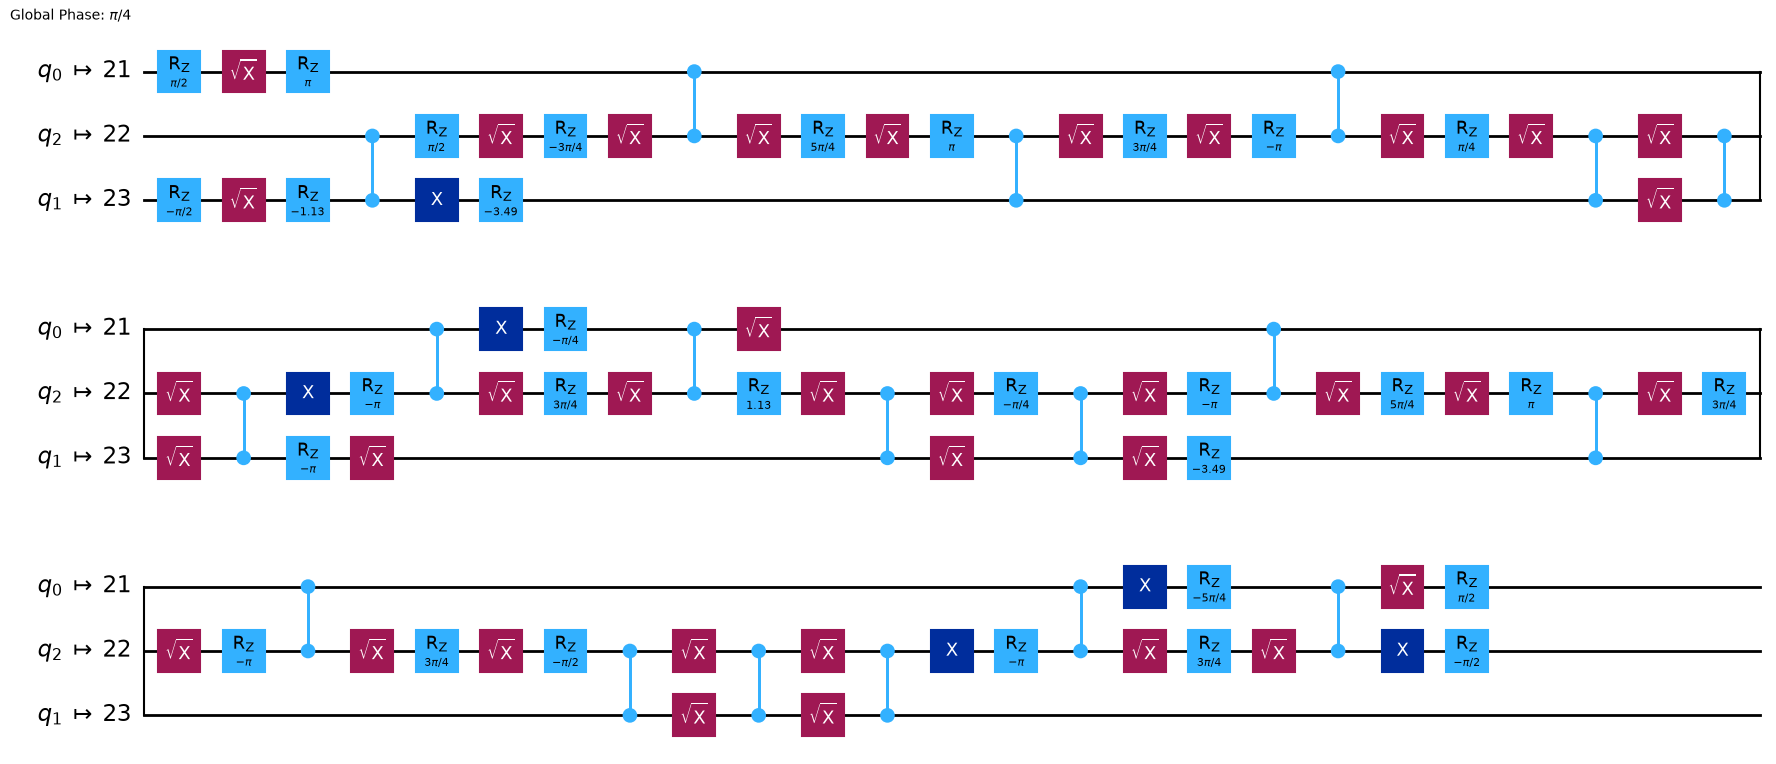

In [83]:
# Transpile for the real backend
quantum_circuit_transpiled = transpile(
    quantum_circuit, backend=backend_fez
)
print("Real backend:", quantum_circuit_transpiled.count_ops())
display(quantum_circuit_transpiled.draw("mpl", idle_wires=False))

**Exercise 4.2:** Repeat Exercise 4.1 for the Grover variant **with an ancilla qubit**, again using **3 data qubits and one Grover step**.

Compare the number of two-qubit gates with the variant without an ancilla qubit. Depending on the backend, these gates may include `cx`, `cz`, or `ecr`.

Original circuit: OrderedDict({'h': 11, 'x': 6, 'mcx': 2, 'z': 1, 'ccx': 1, 'rz': 1})


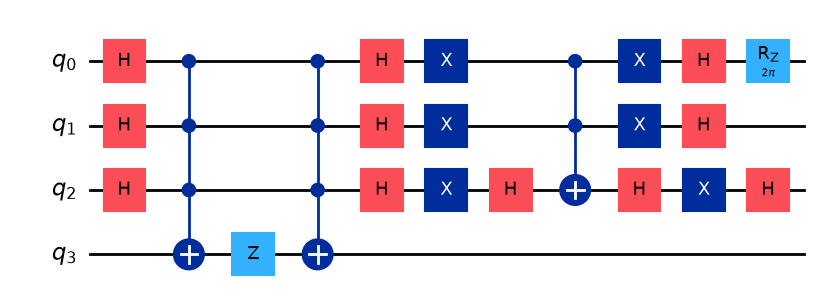

Simulated backend: OrderedDict({'rz': 70, 'cx': 57, 'sx': 32, 'x': 3})


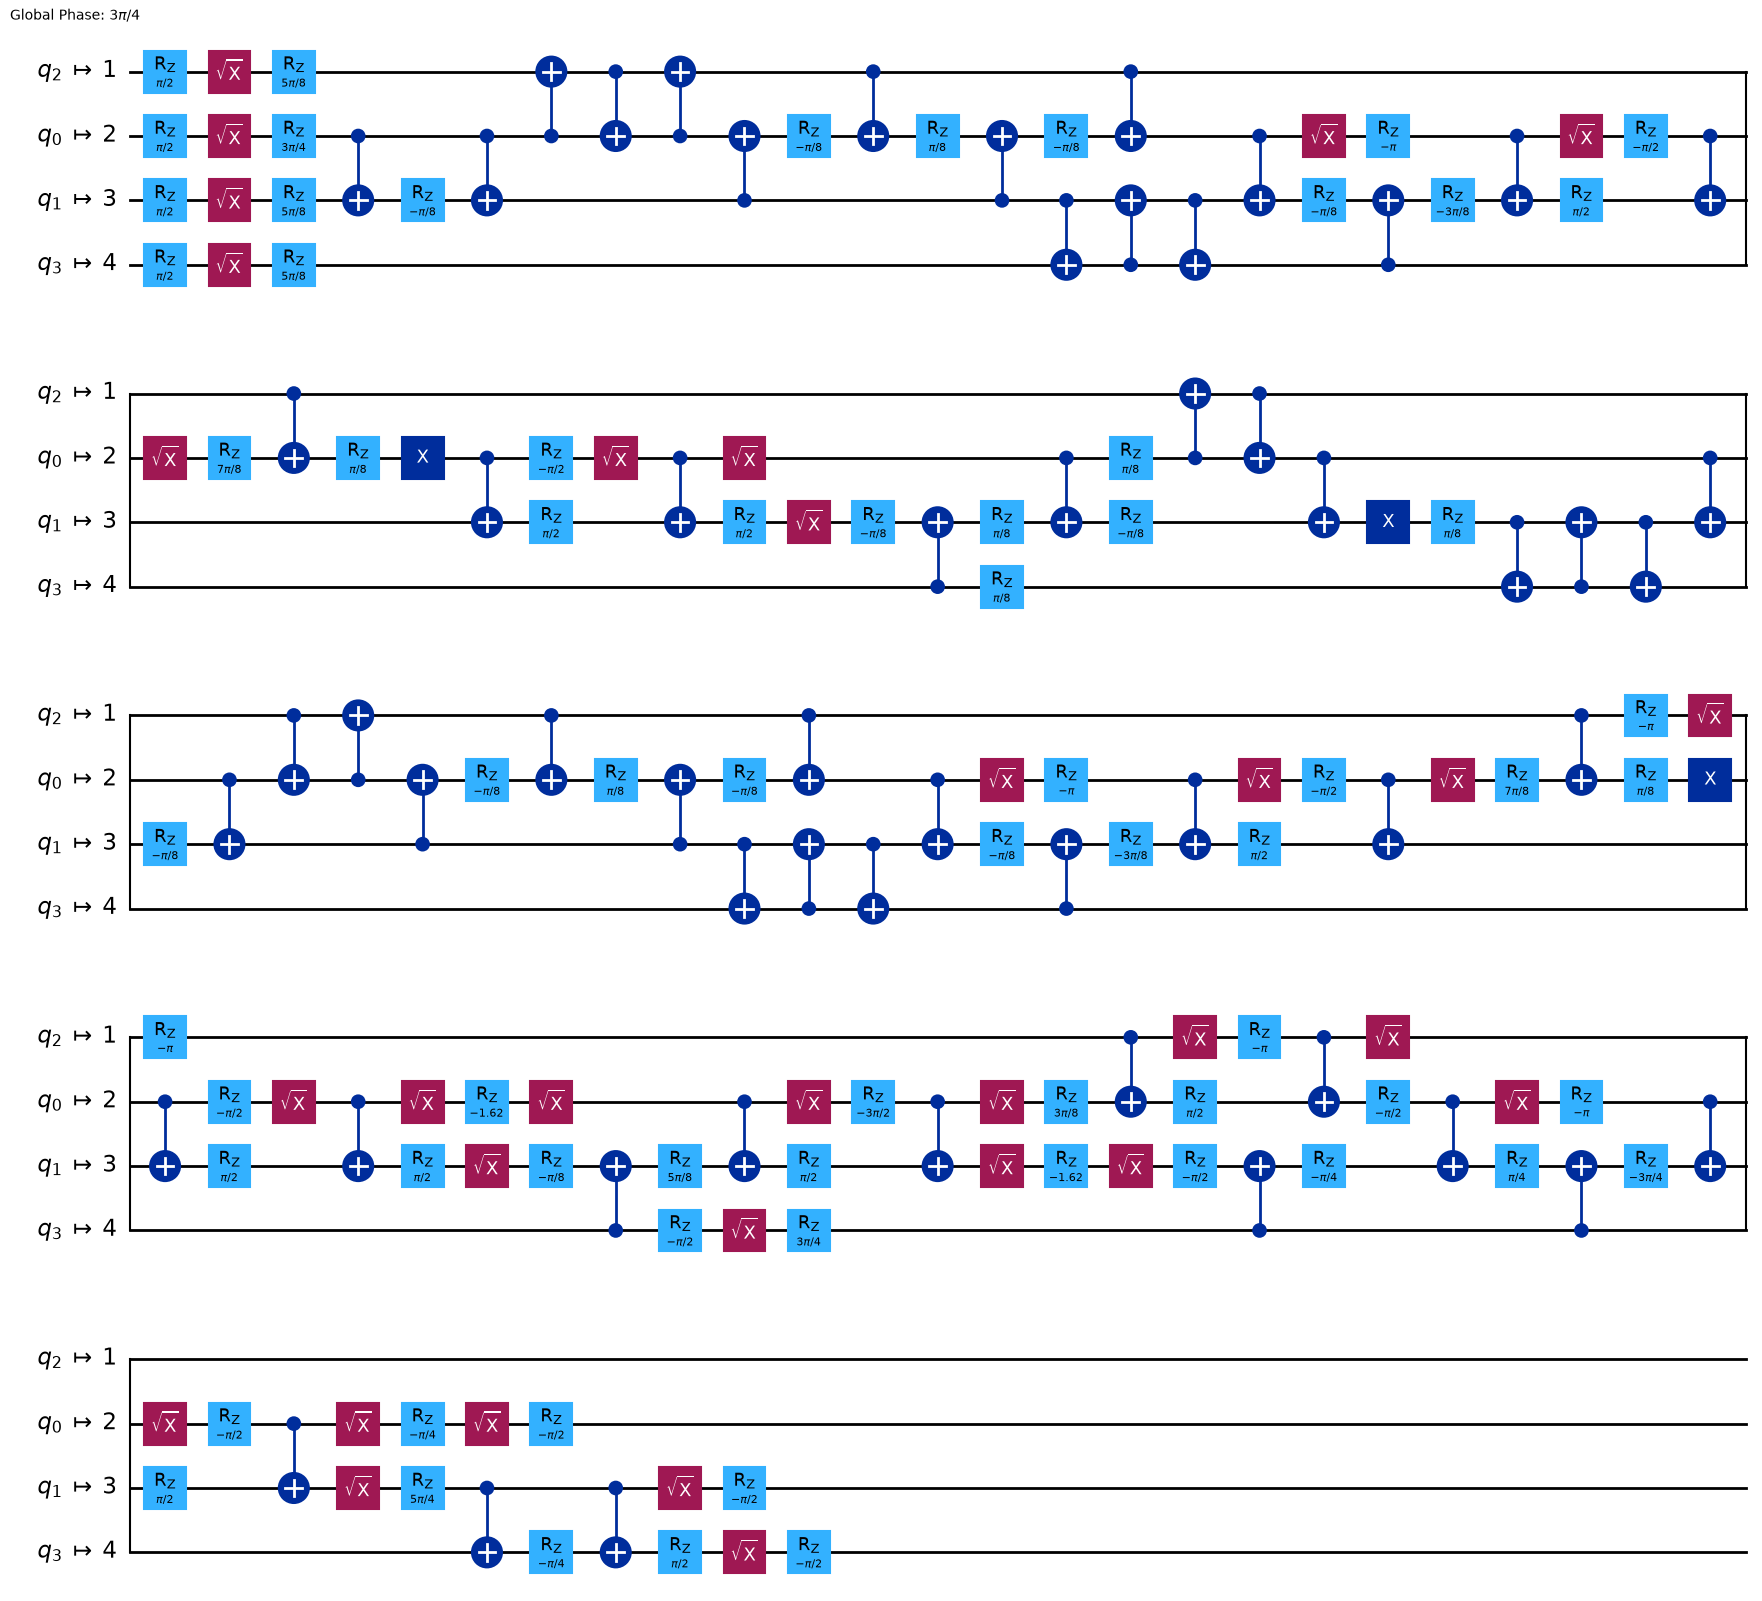

In [84]:
# Grover circuit with an ancilla qubit
quantum_circuit = grover_ancilla(3, 1)
print("Original circuit:", quantum_circuit.count_ops())
display(quantum_circuit.draw("mpl"))

# Transpile for the simulated backend
quantum_circuit_transpiled = transpile(
    quantum_circuit, backend=backend_fake_manila
)
print("Simulated backend:", quantum_circuit_transpiled.count_ops())
display(quantum_circuit_transpiled.draw("mpl", idle_wires=False))

Real backend: OrderedDict({'sx': 100, 'rz': 75, 'cz': 47, 'x': 4})


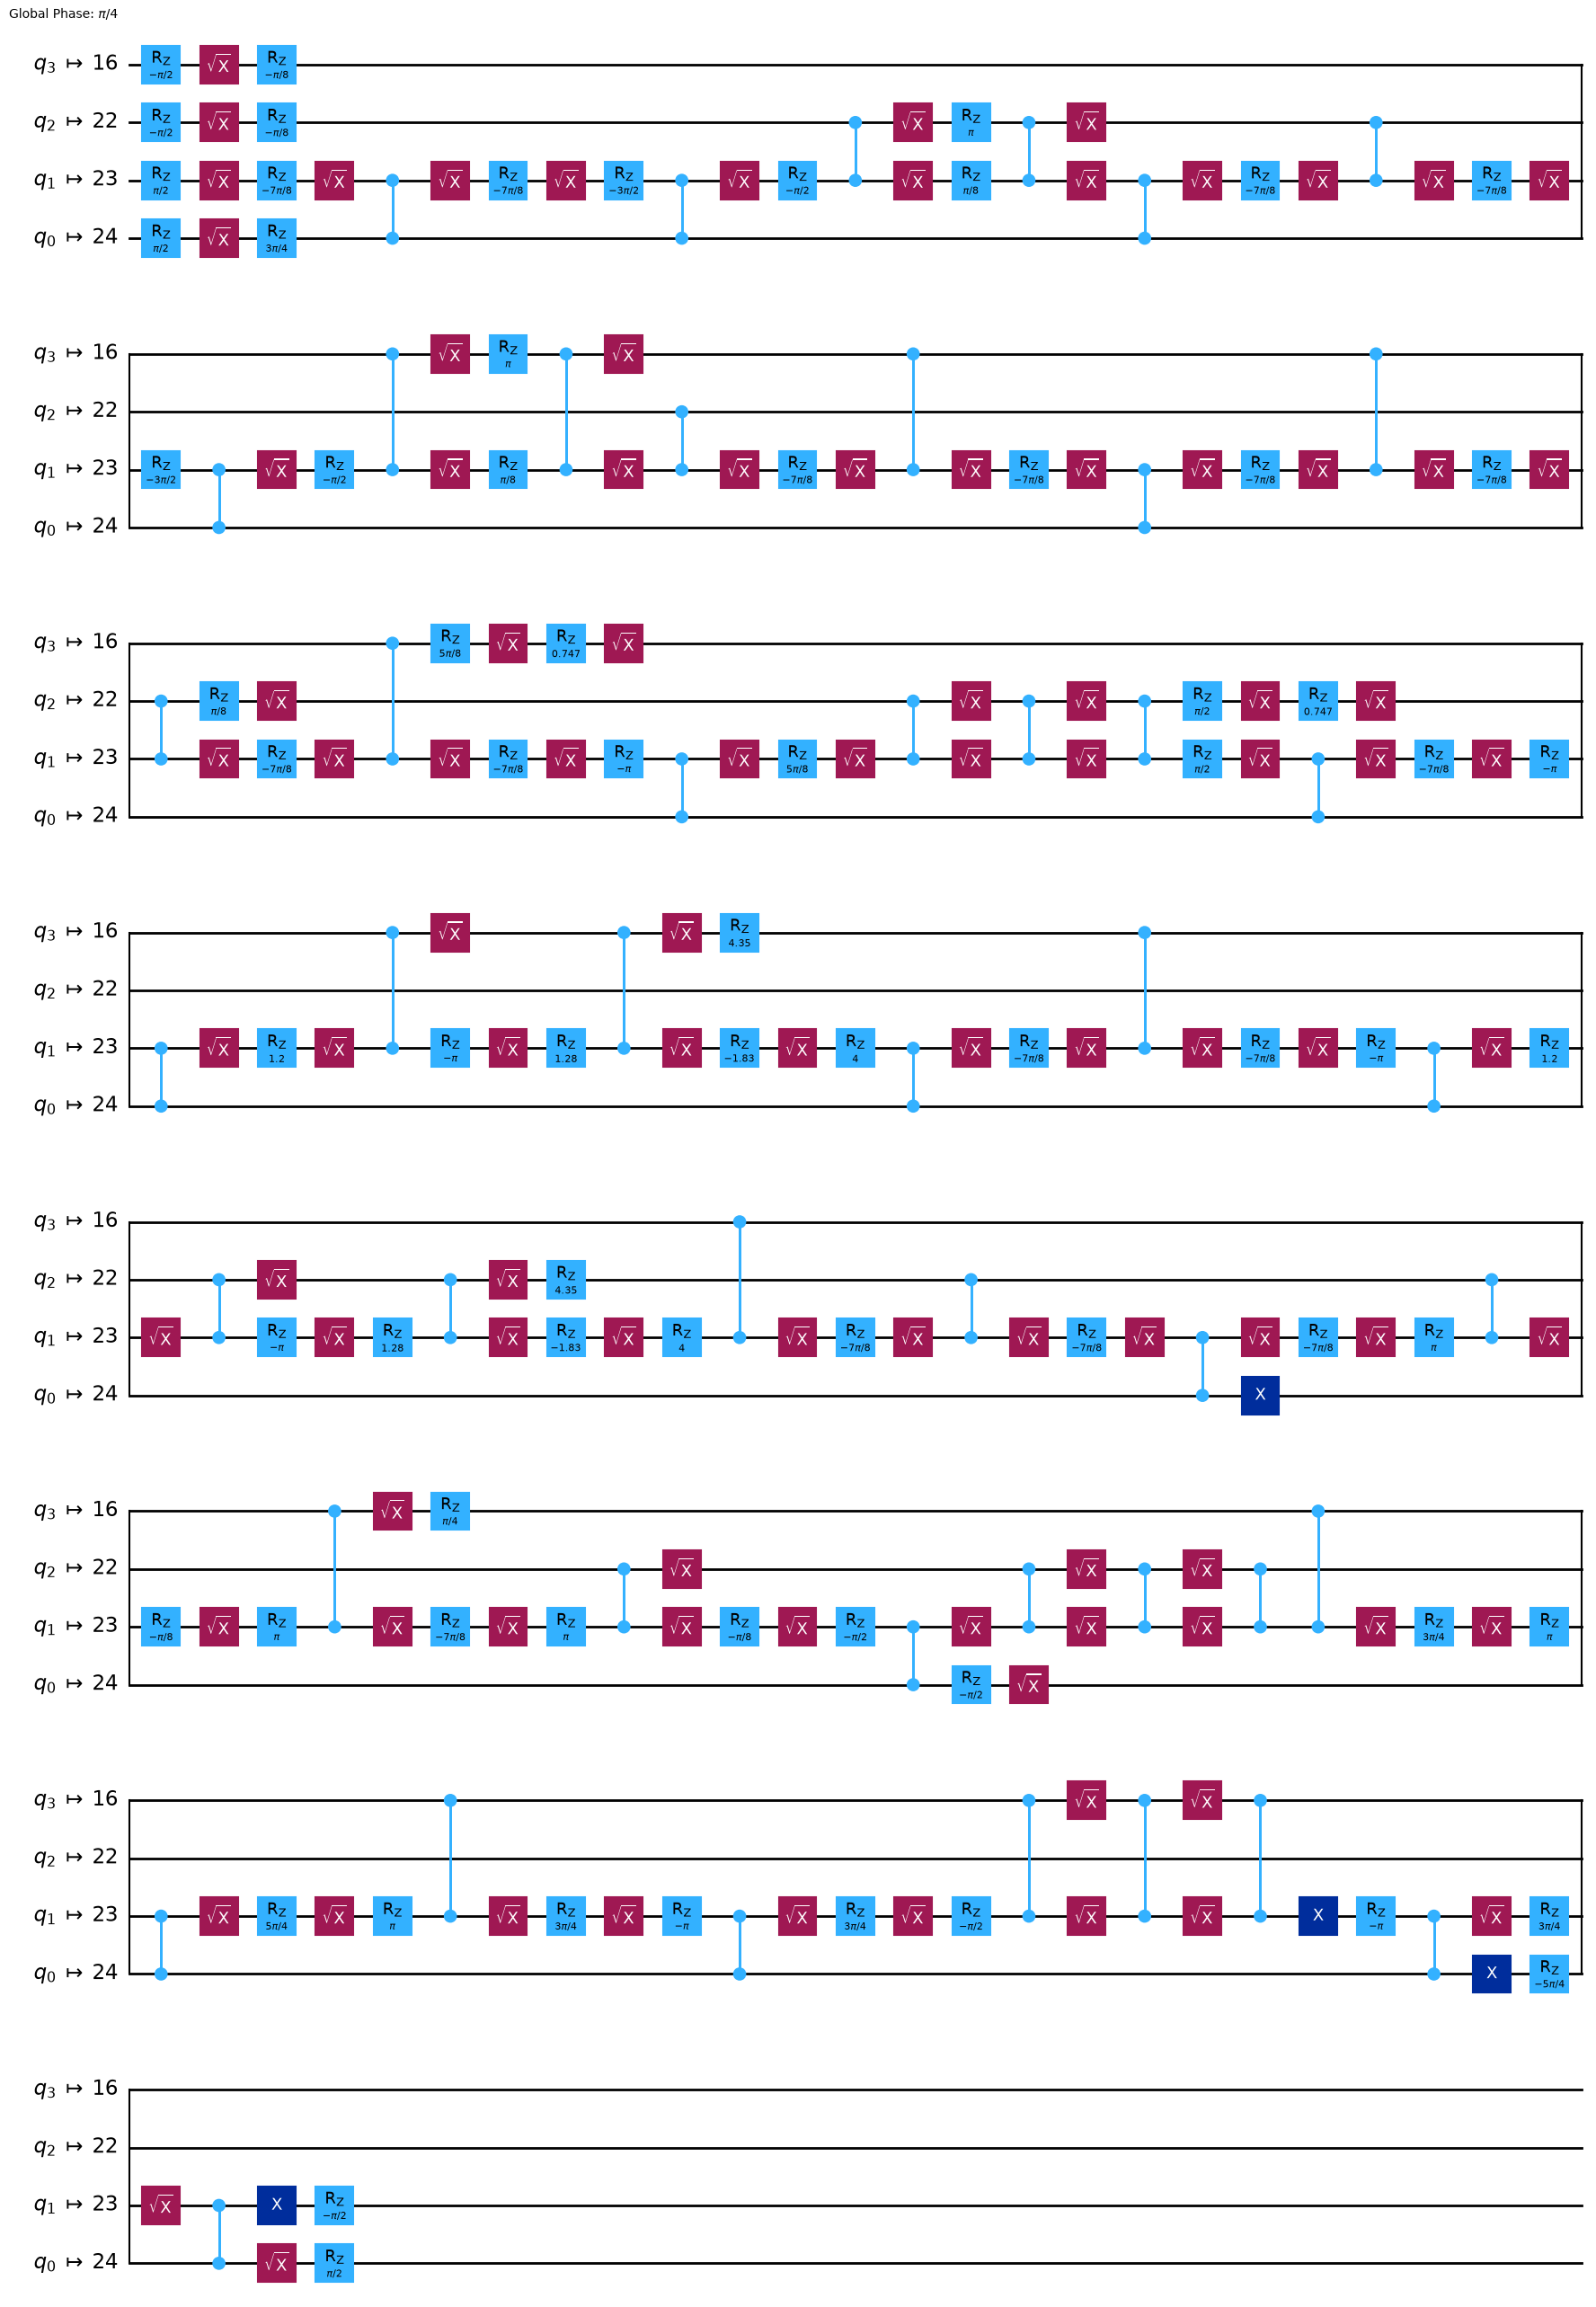

In [85]:
# Transpile for the real backend
quantum_circuit_transpiled = transpile(
    quantum_circuit, backend=backend_fez
)
print("Real backend:", quantum_circuit_transpiled.count_ops())
display(quantum_circuit_transpiled.draw("mpl", idle_wires=False))

### Exercise 5: Running on Simulated Hardware

The following Bell state example shows how to run a circuit using `SamplerV2` on `backend_fake_manila` from Exercise 3.3. Use the steps explained in the comments for your Grover circuits in the following exercises.


In [86]:
from qiskit_ibm_runtime import SamplerV2

# 1. Prepare a Bell state; replace this with Grover for the exercises.
quantum_circuit = QuantumCircuit(2)
quantum_circuit.h(0)
quantum_circuit.cx(0, 1)

# 2. Adjust the bit order and add measurements.
# The data qubits will then appear on the left and any ancillas on the right.
# measure_all() creates the classical measurement register meas.
quantum_circuit = quantum_circuit.reverse_bits()
quantum_circuit.measure_all()

# 3. Transpile for the selected backend.
quantum_circuit_transpiled = transpile(
    quantum_circuit, backend=backend_fake_manila
)

# 4. Set the sampler and the number of measurement repetitions (shots).
# For real hardware, use backend_fez both here AND in step 3.
num_shots = 100
sampler = SamplerV2(
    mode=backend_fake_manila, options={"default_shots": num_shots}
)

# 5. Start the job; pass even a single circuit as a list.
pubs = [quantum_circuit_transpiled]
job = sampler.run(pubs)

# 6. Wait for the result; [0] selects the first circuit.
result = job.result()[0]

# 7. Retrieve the bitstrings and their counts from the meas register.
result.data.meas.get_counts()


{'00': 49, '11': 47, '01': 3, '10': 1}

**Exercise 5.1:** Run Grover **without an ancilla qubit** for **3 data qubits and 2 Grover steps** on `backend_fake_manila`. Use **100 shots**. Which bitstring occurs most often?


In [87]:
from qiskit_ibm_runtime import SamplerV2

num_data_qubits = 3
num_steps = 2
quantum_circuit = grover(num_data_qubits, num_steps)

# Display data qubits on the left and the ancilla qubit, if present, on the right
quantum_circuit = quantum_circuit.reverse_bits()
quantum_circuit.measure_all()
quantum_circuit_transpiled = transpile(quantum_circuit, backend=backend_fake_manila)

num_shots = 100
sampler = SamplerV2(mode=backend_fake_manila, options={"default_shots": num_shots})
job = sampler.run([quantum_circuit_transpiled])
result = job.result()[0]
result.data.meas.get_counts()

{'111': 59,
 '000': 4,
 '001': 8,
 '100': 5,
 '010': 3,
 '110': 12,
 '011': 4,
 '101': 5}

**Exercise 5.2:** Repeat the execution **with an ancilla qubit**, again using **3 data qubits and 2 Grover steps**. Compare the result with Exercise 5.1. The additional bit on the right belongs to the ancilla qubit and should ideally be 0. The target state is therefore `1110`.

In [88]:
num_data_qubits = 3
num_steps = 2
quantum_circuit = grover_ancilla(num_data_qubits, num_steps)

# Display data qubits on the left and the ancilla qubit, if present, on the right
quantum_circuit = quantum_circuit.reverse_bits()
quantum_circuit.measure_all()
quantum_circuit_transpiled = transpile(quantum_circuit, backend=backend_fake_manila)

num_shots = 100
sampler = SamplerV2(mode=backend_fake_manila, options={"default_shots": num_shots})
job = sampler.run([quantum_circuit_transpiled])
result = job.result()[0]
result.data.meas.get_counts()

{'1110': 21,
 '1100': 8,
 '0010': 5,
 '1011': 4,
 '0100': 7,
 '1111': 7,
 '0001': 5,
 '1000': 8,
 '1101': 3,
 '0111': 2,
 '1010': 7,
 '0011': 6,
 '1001': 6,
 '0110': 4,
 '0101': 1,
 '0000': 6}

### Exercise 6: Running on Real Quantum Hardware

Compare the variants with **3 and 4 data qubits**, each **with and without an ancilla qubit**. Follow the steps from Exercise 5 and replace `backend_fake_manila` with `backend_fez` from Exercise 3.2 **in both `transpile` and `SamplerV2`**.

Continue to use **100 shots**. You can also monitor the job status on the [IBM Quantum Platform](https://quantum.cloud.ibm.com/).


**Exercise 6.1:** Run Grover **without an ancilla qubit** for **3 data qubits and 2 Grover steps** on the real hardware. Compare the result with Exercise 5.1.

In [89]:
num_data_qubits = 3
num_steps = 2
quantum_circuit = grover(num_data_qubits, num_steps)

# Display data qubits on the left and the ancilla qubit, if present, on the right
quantum_circuit = quantum_circuit.reverse_bits()
quantum_circuit.measure_all()
quantum_circuit_transpiled = transpile(quantum_circuit, backend=backend_fez)

num_shots = 100
sampler = SamplerV2(mode=backend_fez, options={"default_shots": num_shots})
job = sampler.run([quantum_circuit_transpiled])
result = job.result()[0]
result.data.meas.get_counts()

qiskit_runtime_service.backends:WARNING:2026-11-19 20:52:10,814: Using instance: HHN, plan: open


{'111': 67, '100': 4, '101': 8, '011': 5, '000': 5, '001': 5, '110': 6}

**Exercise 6.2:** Run Grover **with an ancilla qubit** for **3 data qubits and 2 Grover steps** on the real hardware. Compare the result with Exercise 5.2 and with the hardware execution without an ancilla qubit.

In [90]:
num_data_qubits = 3
num_steps = 2
quantum_circuit = grover_ancilla(num_data_qubits, num_steps)

# Display data qubits on the left and the ancilla qubit, if present, on the right
quantum_circuit = quantum_circuit.reverse_bits()
quantum_circuit.measure_all()
quantum_circuit_transpiled = transpile(quantum_circuit, backend=backend_fez)

num_shots = 100
sampler = SamplerV2(mode=backend_fez, options={"default_shots": num_shots})
job = sampler.run([quantum_circuit_transpiled])
result = job.result()[0]
result.data.meas.get_counts()

qiskit_runtime_service.backends:WARNING:2026-11-19 20:52:26,057: Using instance: HHN, plan: open


{'1110': 46,
 '0110': 5,
 '1100': 8,
 '1101': 3,
 '0111': 1,
 '1010': 6,
 '1111': 6,
 '0010': 2,
 '0001': 2,
 '1000': 6,
 '0100': 3,
 '1011': 6,
 '1001': 2,
 '0011': 1,
 '0000': 2,
 '0101': 1}

**Exercise 6.3:** Run Grover **without an ancilla qubit** for **4 data qubits and 3 Grover steps** on the real hardware. Compare the result with the ideal probability from Exercise 1.

In [91]:
num_data_qubits = 4
num_steps = 3
quantum_circuit = grover(num_data_qubits, num_steps)

# Display data qubits on the left and the ancilla qubit, if present, on the right
quantum_circuit = quantum_circuit.reverse_bits()
quantum_circuit.measure_all()
quantum_circuit_transpiled = transpile(quantum_circuit, backend=backend_fez)

num_shots = 100
sampler = SamplerV2(mode=backend_fez, options={"default_shots": num_shots})
job = sampler.run([quantum_circuit_transpiled])
result = job.result()[0]
result.data.meas.get_counts()

qiskit_runtime_service.backends:WARNING:2026-11-19 20:52:36,397: Using instance: HHN, plan: open


{'1111': 46,
 '1011': 3,
 '1101': 5,
 '0101': 5,
 '1010': 4,
 '0111': 5,
 '0011': 4,
 '0010': 3,
 '1001': 4,
 '0110': 3,
 '0000': 3,
 '1110': 6,
 '1100': 4,
 '0001': 1,
 '0100': 2,
 '1000': 2}

**Exercise 6.4:** Run Grover **with an ancilla qubit** for **4 data qubits and 3 Grover steps** on the real hardware. Compare the result with Exercise 6.3. How does the additional ancilla qubit affect the result?

In [92]:
num_data_qubits = 4
num_steps = 3
quantum_circuit = grover_ancilla(num_data_qubits, num_steps)

# Display data qubits on the left and the ancilla qubit, if present, on the right
quantum_circuit = quantum_circuit.reverse_bits()
quantum_circuit.measure_all()
quantum_circuit_transpiled = transpile(quantum_circuit, backend=backend_fez)

num_shots = 100
sampler = SamplerV2(mode=backend_fez, options={"default_shots": num_shots})
job = sampler.run([quantum_circuit_transpiled])
result = job.result()[0]
result.data.meas.get_counts()

qiskit_runtime_service.backends:WARNING:2026-11-19 20:52:57,719: Using instance: HHN, plan: open


{'11110': 13,
 '00110': 4,
 '01010': 5,
 '11100': 3,
 '00100': 5,
 '01100': 7,
 '11111': 4,
 '01101': 4,
 '00000': 2,
 '10100': 6,
 '01000': 4,
 '11001': 1,
 '11000': 1,
 '10011': 5,
 '10111': 2,
 '10110': 3,
 '10010': 2,
 '10101': 2,
 '01110': 4,
 '00011': 1,
 '10001': 1,
 '00010': 4,
 '11010': 2,
 '01111': 1,
 '00101': 4,
 '10000': 6,
 '01001': 2,
 '01011': 1,
 '00001': 1}

### Exercise 7: 2×2 Map Coloring with Grover

We will examine the optimized oracle for a map coloring problem, assemble the Grover circuit, and run it directly on quantum hardware after checking its statevector.

Consider four countries arranged in a 2×2 grid:

$$
\begin{matrix}
A & {-} & B \\
\vert && \vert \\
C & {-} & D
\end{matrix}
$$

Each country is assigned one of two colors: $0 = \text{blue}$ or $1 = \text{red}$. Countries that share an edge must have different colors. Diagonally opposite countries are not considered adjacent. No country's color is fixed in advance.

A valid coloring therefore satisfies

$$
A \neq B,\qquad A \neq C,\qquad B \neq D,\qquad C \neq D.
$$

Data qubits 0, 1, 2, and 3 represent `A`, `B`, `C`, and `D`, in that order. We write a coloring as a bitstring `ABCD`.

In [93]:
from qc_lecture_tools.grover import (
    initial_state,
    amplitude_amplification,
    print_grover_states,
    map_oracle,
)

**Exercise 7.1: Examining the Optimized Oracle**

Run the following cell and examine the imported oracle. It requires **4 data qubits and 4 ancilla qubits**, for a total of **8 qubits**. Qubits 0–3 represent the colors `ABCD`; qubits 4–7 store the four inequalities listed above and start in $\ket{0}$.

Phase marking acts directly on the four qubits that store the conditions. A multi-controlled Z gate is implemented using **H–MCX–H**, so no additional validity qubit is needed.

Use the circuit to explain **compute**, **phase marking**, and **uncompute**. Why does the oracle mark exactly the valid colorings and then return the ancilla qubits to 0?

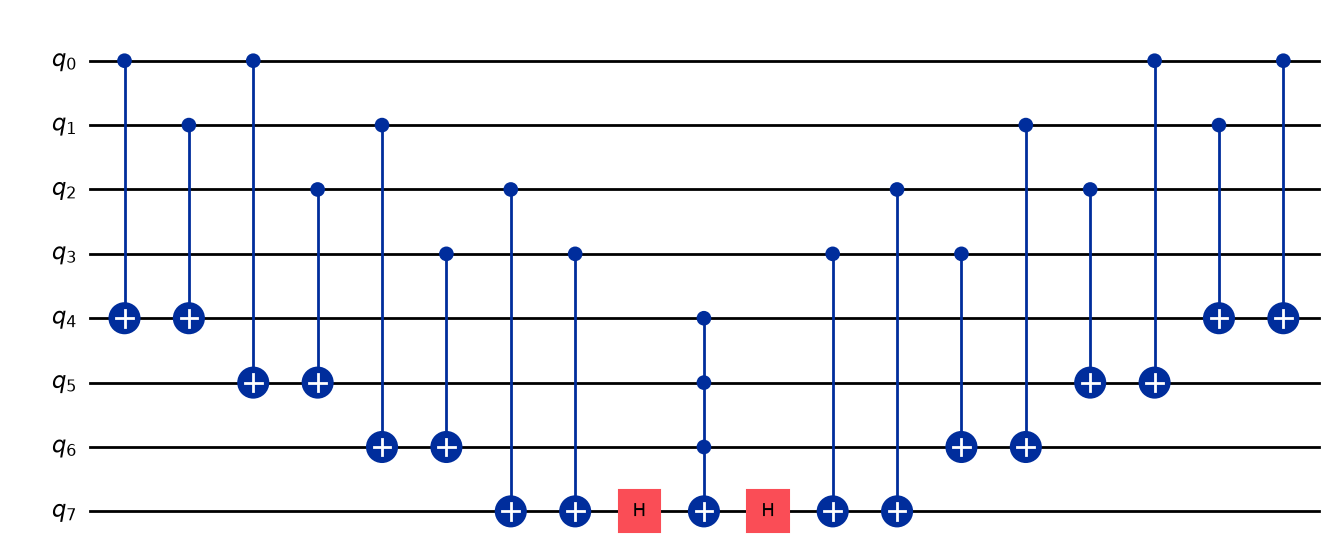

In [94]:
qc_map_oracle = map_oracle()

# Each pair of CX gates checks one inequality.
# H–MCX–H marks the coloring if all four conditions are satisfied.
# Uncompute then returns the four ancilla qubits to 0.
qc_map_oracle.draw("mpl")

**Exercise 7.2: Assembling Grover and Checking the Statevector**

Build the Grover circuit `qc_map` for **two Grover steps**. First, use `initial_state(4, 4)` to prepare a uniform superposition of the four data qubits. Then, for each Grover step, apply `qc_map_oracle` from Exercise 7.1 followed by amplitude amplification using `amplitude_amplification(4, 4)`.

Amplitude amplification acts only on the four data qubits; the four ancilla qubits are not part of the search space.

Check the statevector using `print_grover_states`. Which colorings are valid, and what are their individual measurement probabilities?


In [95]:
# Prepare a uniform superposition of the four data qubits.
qc_map = initial_state(4, 4)

# 1st Grover step: Oracle and amplitude amplification.
qc_map.compose(qc_map_oracle, inplace=True)
qc_map.compose(amplitude_amplification(4, 4), inplace=True)

# 2nd Grover step: Repeat the oracle and amplitude amplification.
qc_map.compose(qc_map_oracle, inplace=True)
qc_map.compose(amplitude_amplification(4, 4), inplace=True)

print_grover_states(qc_map, 4)

# Valid colorings: 0110 and 1001, each with a probability of about 47.27%.


Found basis states with non-zero amplitudes:
0000 0000: -0.06  Probability:  0.00
0001 0000: -0.06  Probability:  0.00
0010 0000: -0.06  Probability:  0.00
0011 0000: -0.06  Probability:  0.00
0100 0000: -0.06  Probability:  0.00
0101 0000: -0.06  Probability:  0.00
0110 0000:  0.69  Probability:  0.47
0111 0000: -0.06  Probability:  0.00
1000 0000: -0.06  Probability:  0.00
1001 0000:  0.69  Probability:  0.47
1010 0000: -0.06  Probability:  0.00
1011 0000: -0.06  Probability:  0.00
1100 0000: -0.06  Probability:  0.00
1101 0000: -0.06  Probability:  0.00
1110 0000: -0.06  Probability:  0.00
1111 0000: -0.06  Probability:  0.00


**Exercise 7.3: Running on Quantum Hardware**

Run the circuit from Exercise 7.2 on `backend_fez` using **1000 shots**. Measure only the **four data qubits 0–3** and display the bitstrings in the order `ABCD`. Do not measure the ancilla qubits.

Use `measure(qubit, classical_bit)` to measure a specific qubit and store the result (0 or 1) in a classical bit. We create the required classical bits using a `ClassicalRegister`:

```python
from qiskit import ClassicalRegister

# 1. Copy the circuit and create four classical measurement bits.
quantum_circuit = qc_map.copy()
quantum_circuit.add_register(ClassicalRegister(4, "meas"))

# 2. Measure a single qubit: qubit 0 into classical bit 3.
quantum_circuit.measure(0, 3)

# 3. Measure the remaining qubits: the list entries are paired.
# Qubit 1 into bit 2, qubit 2 into bit 1, and qubit 3 into bit 0.
quantum_circuit.measure([1, 2, 3], [2, 1, 0])
```

Qiskit displays classical bit 3 on the left and bit 0 on the right. With this mapping, we read the result as `ABCD`. The register is still called `meas`; use `result.data.meas.get_counts()` to retrieve the counts.

After these individual measurements, proceed directly to `transpile` and `SamplerV2`; the bit order is already determined by the mapping.

Display the measured probability of each valid coloring, `0110` and `1001`. Compare these probabilities with the ideal values from Exercise 7.2.


In [96]:
from qiskit import ClassicalRegister

# 1. Measure only the four data qubits; display results in the order ABCD.
quantum_circuit = qc_map.copy()
# The measurement register is still called meas and contains four bits.
quantum_circuit.add_register(ClassicalRegister(4, "meas"))
quantum_circuit.measure([0, 1, 2, 3], [3, 2, 1, 0])

# 2. Transpile for the hardware backend.
quantum_circuit_transpiled = transpile(quantum_circuit, backend=backend_fez)

# 3. Run the circuit as in the previous exercises.
num_shots = 1000
sampler = SamplerV2(mode=backend_fez, options={"default_shots": num_shots})
job = sampler.run([quantum_circuit_transpiled])
result = job.result()[0]

# 4. Display counts from the meas register and individual probabilities.
counts_map = result.data.meas.get_counts()
# Probability = bitstring count / number of shots.
print("P(0110):", counts_map.get("0110", 0) / num_shots)
print("P(1001):", counts_map.get("1001", 0) / num_shots)


qiskit_runtime_service.backends:WARNING:2026-11-19 20:53:06,583: Using instance: HHN, plan: open


P(0110): 0.05
P(1001): 0.061


**Exercise 7.4: Comparing Dynamical Decoupling**

**Dynamical decoupling (DD)** can reduce noise while qubits are idle by inserting additional pulses.

Use the circuit already transpiled in Exercise 7.3. Copy the code that creates the sampler and runs the circuit. Immediately after initializing the sampler and before starting the job, add only this line:

```python
sampler.options.dynamical_decoupling.enable = True
```

Save the new counts as `counts_map_dd`. For both solutions, compare the measurement probabilities without and with DD.

For more information, see the [IBM documentation on sampler options](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/sampler-options).


In [97]:
num_shots = 1000
sampler = SamplerV2(mode=backend_fez, options={"default_shots": num_shots})
# The only additional setting compared with Exercise 7.3:
sampler.options.dynamical_decoupling.enable = True
job = sampler.run([quantum_circuit_transpiled])
result = job.result()[0]

counts_map_dd = result.data.meas.get_counts()
print("P(0110):", counts_map_dd.get("0110", 0) / num_shots)
print("P(1001):", counts_map_dd.get("1001", 0) / num_shots)


qiskit_runtime_service.backends:WARNING:2026-11-19 20:53:17,486: Using instance: HHN, plan: open


P(0110): 0.141
P(1001): 0.182


**Comparison as a Bar Chart**

The chart compares the measurement counts without and with DD.


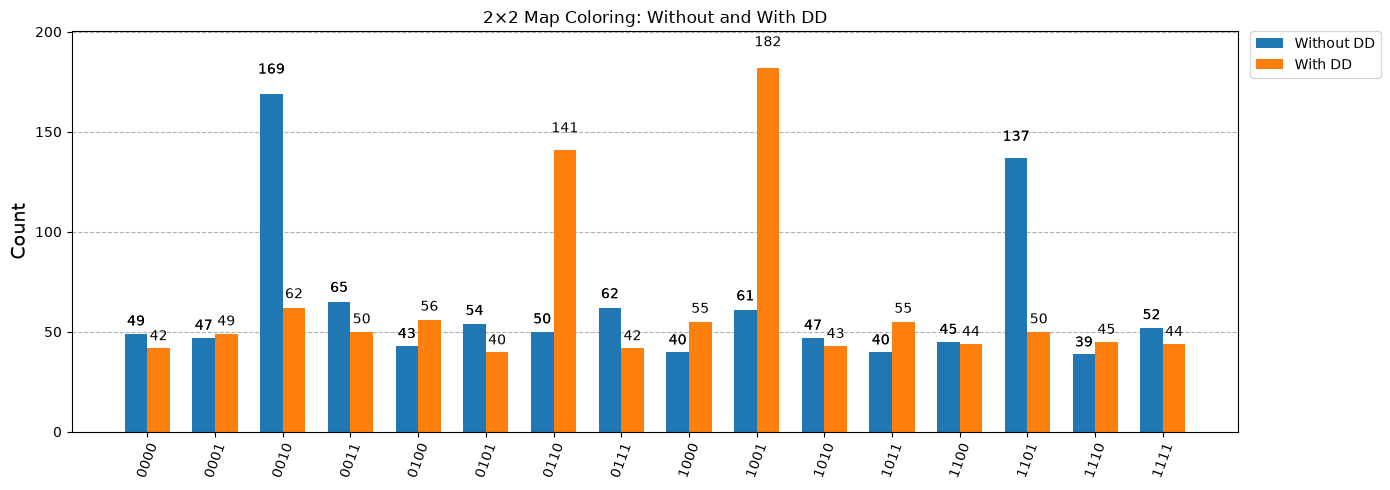

In [98]:
from qiskit.visualization import plot_histogram

plot_histogram(
    [counts_map, counts_map_dd],
    legend=["Without DD", "With DD"],
    figsize=(14, 5),
    title="2×2 Map Coloring: Without and With DD",
)
